Проводятся 8 экспериментов:
- ResNet18: случайные веса / ImageNet;
- VGG16-BN: случайные веса / ImageNet;
- MobileNetV3-Small: случайные веса / ImageNet;
- EfficientNet-B0: случайные веса / ImageNet.

In [16]:
import os
import copy
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("Устройство:", DEVICE)
if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
    print("Память GPU:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), "GB")

# Основные гиперпараметры
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20                 
NUM_WORKERS = 0            # 0 обычно надёжнее в Jupyter на Windows
LEARNING_RATE_SCRATCH = 1e-3
LEARNING_RATE_PRETRAINED = 1e-4

PIN_MEMORY = DEVICE.type == "cuda"

PyTorch: 2.11.0+cu128
CUDA доступна: True
Устройство: cuda
Видеокарта: NVIDIA GeForce RTX 4060 Ti
Память GPU: 16.0 GB



Поиск папки с датасетом

Ожидаются шесть классов: `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`.

In [17]:
DATA_ROOT = Path("./")  # Например: Path("./Garbage classification")

EXPECTED_CLASSES = {"cardboard", "glass", "metal", "paper", "plastic", "trash"}

def find_dataset_folder(root: Path):
    root = root.resolve()
    candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]
    for folder in candidates:
        try:
            subdirs = {p.name.lower() for p in folder.iterdir() if p.is_dir()}
        except PermissionError:
            continue
        if EXPECTED_CLASSES.issubset(subdirs):
            return folder
    return None

DATA_DIR = find_dataset_folder(DATA_ROOT)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Не найдена папка с шестью классами. Измените DATA_ROOT на путь к распакованному датасету."
    )

print("Папка датасета:", DATA_DIR)

Папка датасета: E:\РАБОСИЙ СТОЛ\ВУЗ\Глубокое обучение\Lab3 Erasov\dataset



Загрузка данных и разделение 70/15/15


In [18]:
base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
class_to_idx = base_dataset.class_to_idx

print("Классы:", class_names)
print("Соответствие классов индексам:", class_to_idx)
print("Всего изображений:", len(base_dataset))

all_paths = [sample[0] for sample in base_dataset.samples]
all_labels = np.array([sample[1] for sample in base_dataset.samples])

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print("\nРазмеры выборок:")
print("Обучающая:", len(train_paths))
print("Валидационная:", len(val_paths))
print("Тестовая:", len(test_paths))
print("\nФорма меток:")
print("Обучающие:", train_labels.shape)
print("Валидационные:", val_labels.shape)
print("Тестовые:", test_labels.shape)

Классы: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Соответствие классов индексам: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
Всего изображений: 2527

Размеры выборок:
Обучающая: 1768
Валидационная: 379
Тестовая: 380

Форма меток:
Обучающие: (1768,)
Валидационные: (379,)
Тестовые: (380,)


In [19]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class GarbageDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        label = int(self.labels[index])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

train_dataset = GarbageDataset(train_paths, train_labels, train_transform)
val_dataset = GarbageDataset(val_paths, val_labels, eval_transform)
test_dataset = GarbageDataset(test_paths, test_labels, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

sample_image, sample_label = train_dataset[0]
print("Форма одного изображения:", sample_image.shape)
print("Метка одного изображения:", sample_label, "-", class_names[sample_label])
print("Количество меток в обучающей выборке:", len(train_dataset))

Форма одного изображения: torch.Size([3, 224, 224])
Метка одного изображения: 4 - plastic
Количество меток в обучающей выборке: 1768


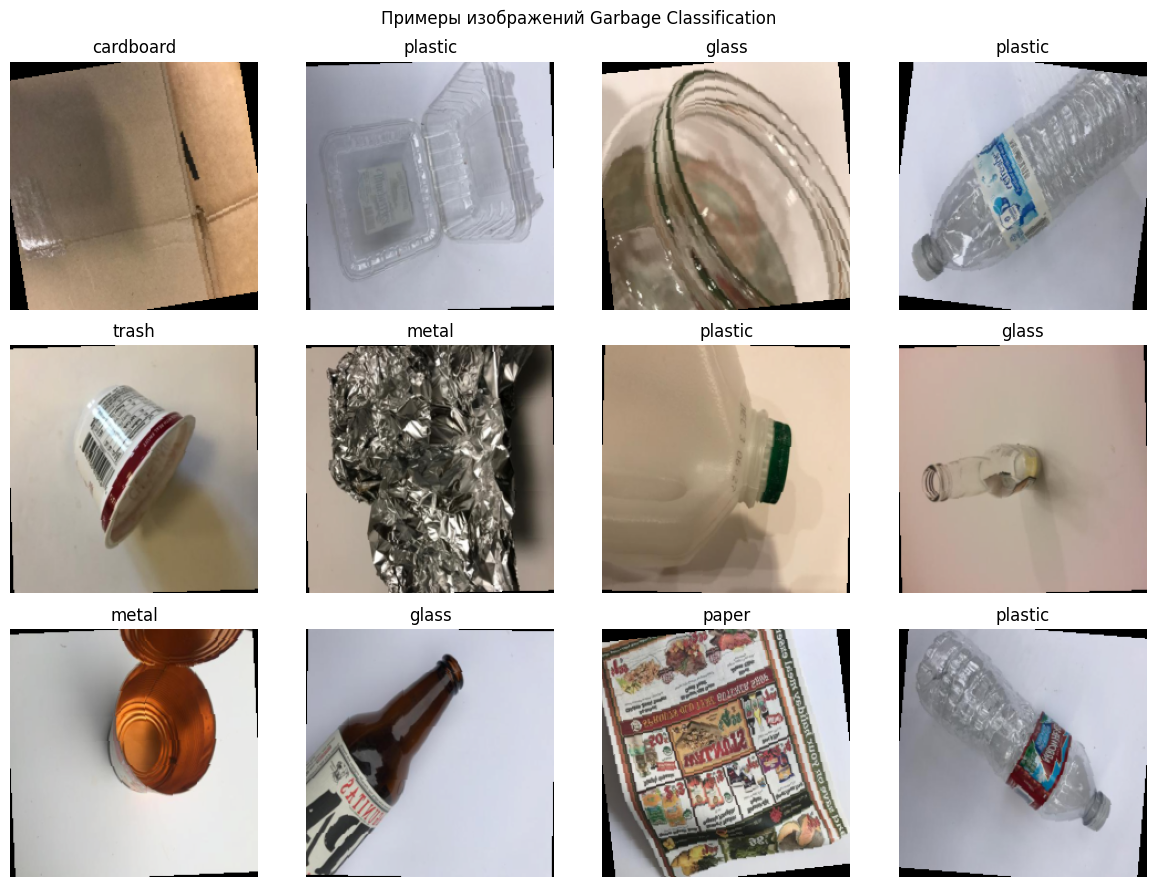

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, index in zip(axes.flat, np.random.choice(len(train_dataset), 12, replace=False)):
    image_tensor, label = train_dataset[index]
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    image = np.clip(image, 0, 1)
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.suptitle("Примеры изображений Garbage Classification")
plt.tight_layout()
plt.show()

In [21]:
NUM_CLASSES = len(class_names)

def build_resnet18(pretrained):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def build_vgg16_bn(pretrained):
    weights = models.VGG16_BN_Weights.DEFAULT if pretrained else None
    model = models.vgg16_bn(weights=weights)
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, NUM_CLASSES)
    return model

def build_mobilenet_v3_small(pretrained):
    weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
    model = models.mobilenet_v3_small(weights=weights)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, NUM_CLASSES)
    return model

def build_efficientnet_b0(pretrained):
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    return model

MODEL_BUILDERS = {
    "ResNet18": build_resnet18,
    "VGG16-BN": build_vgg16_bn,
    "MobileNetV3-Small": build_mobilenet_v3_small,
    "EfficientNet-B0": build_efficientnet_b0
}

print("Будут проведены эксперименты для моделей:", list(MODEL_BUILDERS.keys()))

Будут проведены эксперименты для моделей: ['ResNet18', 'VGG16-BN', 'MobileNetV3-Small', 'EfficientNet-B0']



После каждой эпохи рассчитывается Macro F1-score на валидационной выборке. Для выбора лучшей версии модели используется именно валидационный Macro F1-score. Тестовая выборка не используется при подборе модели и оценивается только после завершения обучения конкретного эксперимента.

In [22]:
criterion = nn.CrossEntropyLoss()

def calculate_macro_f1(model, loader):
    model.eval()
    all_targets = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)
            all_targets.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    macro_f1 = f1_score(
        all_targets, all_predictions,
        average="macro", zero_division=0
    )
    return average_loss, macro_f1, np.array(all_targets), np.array(all_predictions)


def train_one_experiment(model_name, pretrained):
    experiment_name = f"{model_name} | {'ImageNet' if pretrained else 'Random'}"
    print("\n" + "=" * 75)
    print("Эксперимент:", experiment_name)

    model = MODEL_BUILDERS[model_name](pretrained=pretrained).to(DEVICE)
    learning_rate = LEARNING_RATE_PRETRAINED if pretrained else LEARNING_RATE_SCRATCH
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

    history = {"val_f1": [], "val_loss": []}
    best_f1 = -1.0
    best_state = None
    start_time = time.time()

    for epoch in range(EPOCHS):
        epoch_start = time.time()
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / len(train_loader.dataset)
        train_accuracy = correct / total

        val_loss, val_f1, _, _ = calculate_macro_f1(model, val_loader)
        history["val_f1"].append(val_f1)
        history["val_loss"].append(val_loss)
        epoch_time = time.time() - epoch_start

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"Эпоха {epoch + 1:02d}/{EPOCHS} | "
            f"Ошибка обучения: {train_loss:.4f} | "
            f"Точность обучения: {train_accuracy * 100:.2f}% | "
            f"Ошибка валидации: {val_loss:.4f} | "
            f"val Macro F1: {val_f1:.4f} | "
            f"Время: {epoch_time:.1f} сек."
        )

    elapsed = time.time() - start_time

    model.load_state_dict(best_state)
    test_loss, test_f1, y_true, y_pred = calculate_macro_f1(model, test_loader)

    print(f"Лучший validation Macro F1: {best_f1:.4f}")
    print(f"Test Macro F1: {test_f1:.4f}")
    print(f"Время эксперимента: {elapsed / 60:.1f} мин.")

    result = {
        "model": model_name,
        "experiment": "ImageNet" if pretrained else "Random",
        "name": experiment_name,
        "history": history,
        "best_val_f1": best_f1,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "time_min": elapsed / 60,
        "y_true": y_true,
        "y_pred": y_pred
    }

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return result

Каждая модель создаётся заново для каждого режима. Поэтому эксперимент со случайными весами не наследует параметры от эксперимента с ImageNet, и наоборот.

In [23]:
results = []

for model_name in MODEL_BUILDERS:
    # Эксперимент 1: обучение со случайными весами
    results.append(train_one_experiment(model_name, pretrained=False))

    # Эксперимент 2: перенос знаний с ImageNet
    results.append(train_one_experiment(model_name, pretrained=True))

print("\nВсе эксперименты завершены.")


Эксперимент: ResNet18 | Random
Эпоха 01/20 | Ошибка обучения: 1.5052 | Точность обучения: 42.99% | Ошибка валидации: 1.3547 | val Macro F1: 0.3677 | Время: 8.3 сек.
Эпоха 02/20 | Ошибка обучения: 1.2588 | Точность обучения: 52.38% | Ошибка валидации: 1.4211 | val Macro F1: 0.4370 | Время: 7.9 сек.
Эпоха 03/20 | Ошибка обучения: 1.1907 | Точность обучения: 55.54% | Ошибка валидации: 1.1502 | val Macro F1: 0.5168 | Время: 7.9 сек.
Эпоха 04/20 | Ошибка обучения: 1.1557 | Точность обучения: 56.96% | Ошибка валидации: 1.3707 | val Macro F1: 0.4692 | Время: 7.9 сек.
Эпоха 05/20 | Ошибка обучения: 1.0973 | Точность обучения: 59.11% | Ошибка валидации: 1.5409 | val Macro F1: 0.3805 | Время: 7.9 сек.
Эпоха 06/20 | Ошибка обучения: 1.0568 | Точность обучения: 58.99% | Ошибка валидации: 1.1333 | val Macro F1: 0.5575 | Время: 7.9 сек.
Эпоха 07/20 | Ошибка обучения: 1.0155 | Точность обучения: 62.78% | Ошибка валидации: 1.1792 | val Macro F1: 0.5053 | Время: 7.9 сек.
Эпоха 08/20 | Ошибка обучения:

100.0%


Эпоха 01/20 | Ошибка обучения: 0.8392 | Точность обучения: 68.61% | Ошибка валидации: 0.4372 | val Macro F1: 0.8025 | Время: 27.2 сек.
Эпоха 02/20 | Ошибка обучения: 0.2937 | Точность обучения: 89.65% | Ошибка валидации: 0.3206 | val Macro F1: 0.8846 | Время: 26.9 сек.
Эпоха 03/20 | Ошибка обучения: 0.1875 | Точность обучения: 93.44% | Ошибка валидации: 0.3090 | val Macro F1: 0.8719 | Время: 27.1 сек.
Эпоха 04/20 | Ошибка обучения: 0.1007 | Точность обучения: 96.83% | Ошибка валидации: 0.3800 | val Macro F1: 0.8688 | Время: 26.9 сек.
Эпоха 05/20 | Ошибка обучения: 0.0884 | Точность обучения: 96.78% | Ошибка валидации: 0.3846 | val Macro F1: 0.8913 | Время: 26.9 сек.
Эпоха 06/20 | Ошибка обучения: 0.0891 | Точность обучения: 97.23% | Ошибка валидации: 0.4170 | val Macro F1: 0.8849 | Время: 27.7 сек.
Эпоха 07/20 | Ошибка обучения: 0.0849 | Точность обучения: 97.23% | Ошибка валидации: 0.4503 | val Macro F1: 0.8596 | Время: 27.3 сек.
Эпоха 08/20 | Ошибка обучения: 0.0664 | Точность обучен

100.0%


Эпоха 01/20 | Ошибка обучения: 1.3765 | Точность обучения: 50.40% | Ошибка валидации: 0.9881 | val Macro F1: 0.5937 | Время: 7.5 сек.
Эпоха 02/20 | Ошибка обучения: 0.7497 | Точность обучения: 75.85% | Ошибка валидации: 0.6583 | val Macro F1: 0.7171 | Время: 7.1 сек.
Эпоха 03/20 | Ошибка обучения: 0.4872 | Точность обучения: 84.95% | Ошибка валидации: 0.4779 | val Macro F1: 0.8188 | Время: 7.4 сек.
Эпоха 04/20 | Ошибка обучения: 0.3597 | Точность обучения: 88.52% | Ошибка валидации: 0.3970 | val Macro F1: 0.8450 | Время: 7.0 сек.
Эпоха 05/20 | Ошибка обучения: 0.2669 | Точность обучения: 91.63% | Ошибка валидации: 0.3413 | val Macro F1: 0.8586 | Время: 7.0 сек.
Эпоха 06/20 | Ошибка обучения: 0.2294 | Точность обучения: 92.31% | Ошибка валидации: 0.3303 | val Macro F1: 0.8725 | Время: 6.7 сек.
Эпоха 07/20 | Ошибка обучения: 0.1468 | Точность обучения: 95.48% | Ошибка валидации: 0.3676 | val Macro F1: 0.8472 | Время: 6.9 сек.
Эпоха 08/20 | Ошибка обучения: 0.1243 | Точность обучения: 96.

100.0%


Эпоха 01/20 | Ошибка обучения: 1.3709 | Точность обучения: 57.01% | Ошибка валидации: 0.8533 | val Macro F1: 0.6783 | Время: 10.3 сек.
Эпоха 02/20 | Ошибка обучения: 0.6772 | Точность обучения: 79.86% | Ошибка валидации: 0.5004 | val Macro F1: 0.7784 | Время: 10.7 сек.
Эпоха 03/20 | Ошибка обучения: 0.3955 | Точность обучения: 88.01% | Ошибка валидации: 0.3719 | val Macro F1: 0.7987 | Время: 10.5 сек.
Эпоха 04/20 | Ошибка обучения: 0.2693 | Точность обучения: 91.69% | Ошибка валидации: 0.3248 | val Macro F1: 0.8340 | Время: 10.8 сек.
Эпоха 05/20 | Ошибка обучения: 0.1887 | Точность обучения: 95.31% | Ошибка валидации: 0.2855 | val Macro F1: 0.8583 | Время: 10.3 сек.
Эпоха 06/20 | Ошибка обучения: 0.1318 | Точность обучения: 96.61% | Ошибка валидации: 0.2684 | val Macro F1: 0.8826 | Время: 10.2 сек.
Эпоха 07/20 | Ошибка обучения: 0.1005 | Точность обучения: 97.62% | Ошибка валидации: 0.2511 | val Macro F1: 0.9040 | Время: 10.5 сек.
Эпоха 08/20 | Ошибка обучения: 0.0825 | Точность обучен


На графике отображается изменение Macro F1-score после каждой эпохи для всех восьми экспериментов.

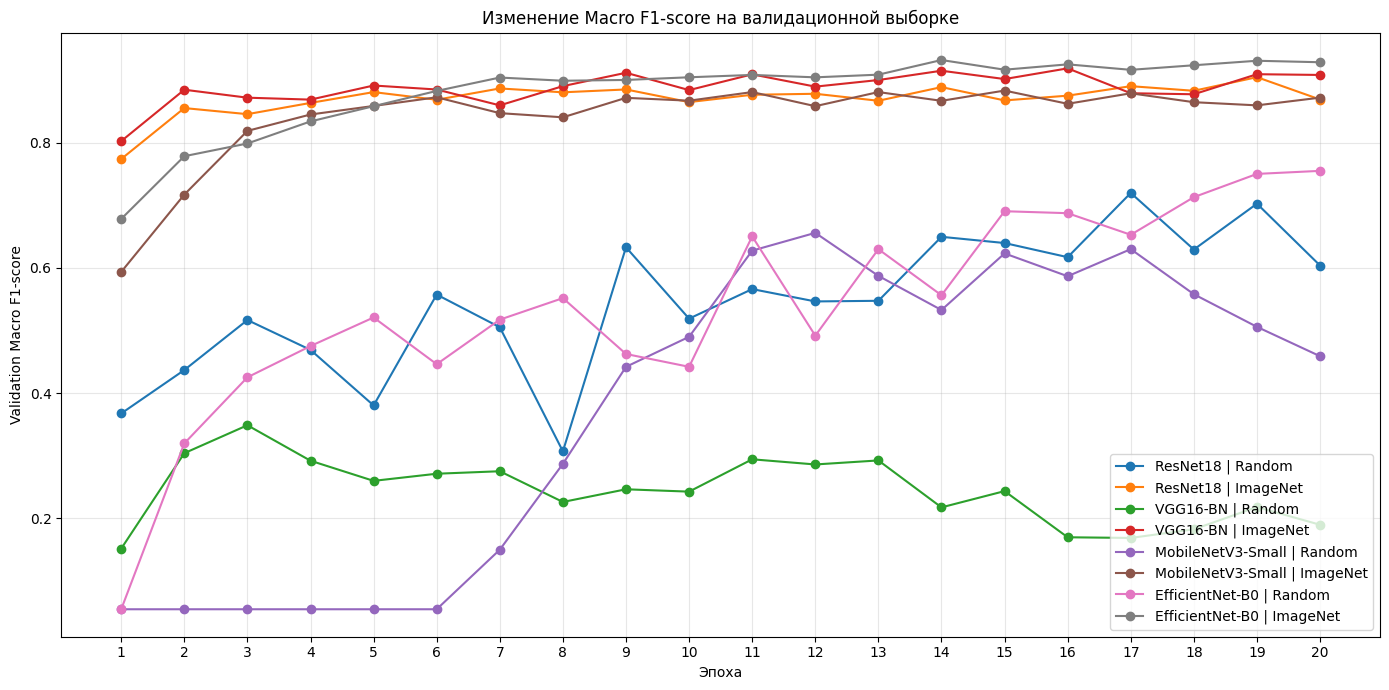

In [24]:
plt.figure(figsize=(14, 7))
for result in results:
    plt.plot(
        range(1, len(result["history"]["val_f1"]) + 1),
        result["history"]["val_f1"],
        marker="o",
        label=result["name"]
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation Macro F1-score")
plt.title("Изменение Macro F1-score на валидационной выборке")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Для итогового сравнения используется тестовый Macro F1-score лучшей по валидации версии каждой модели.

In [25]:
results_table = pd.DataFrame([
    {
        "Модель": result["model"],
        "Тип эксперимента": result["experiment"],
        "Test Macro F1": result["test_f1"],
        "Best Val Macro F1": result["best_val_f1"],
        "Время, мин": result["time_min"]
    }
    for result in results
]).sort_values("Test Macro F1", ascending=False)

display(results_table)

,Модель,Тип эксперимента,Test Macro F1,Best Val Macro F1,"Время, мин"
7,EfficientNet-B0,ImageNet,0.921316,0.931968,3.576298
1,ResNet18,ImageNet,0.912207,0.904600,2.852905
3,VGG16-BN,ImageNet,0.905079,0.918672,9.213998
5,MobileNetV3-Small,ImageNet,0.889698,0.883189,2.383077
6,EfficientNet-B0,Random,0.732569,0.755011,3.499296
0,ResNet18,Random,0.656238,0.719741,2.709376
4,MobileNetV3-Small,Random,0.650926,0.656040,2.443641
2,VGG16-BN,Random,0.324426,0.348868,9.208223


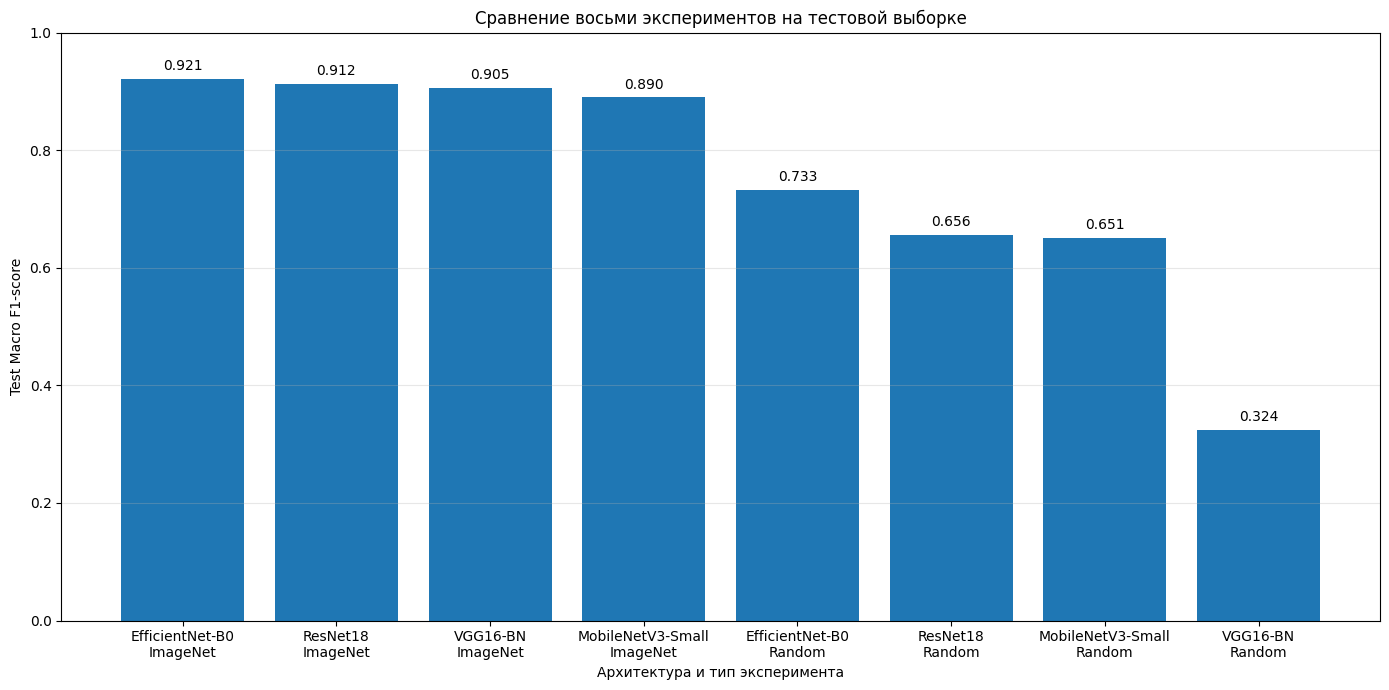

In [26]:
plot_data = results_table.copy()
plot_data["Подпись"] = plot_data["Модель"] + "\n" + plot_data["Тип эксперимента"]

plt.figure(figsize=(14, 7))
bars = plt.bar(plot_data["Подпись"], plot_data["Test Macro F1"])
plt.ylabel("Test Macro F1-score")
plt.xlabel("Архитектура и тип эксперимента")
plt.title("Сравнение восьми экспериментов на тестовой выборке")
plt.ylim(0, 1.0)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_data["Test Macro F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Выбирается эксперимент с максимальным тестовым Macro F1-score. Дополнительно выводится отчёт по каждому классу.

In [27]:
best_result = max(results, key=lambda item: item["test_f1"])
print("Лучший эксперимент:", best_result["name"])
print(f"Test Macro F1-score: {best_result['test_f1']:.4f}")

print("\nClassification report:")
print(classification_report(
    best_result["y_true"],
    best_result["y_pred"],
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

Лучший эксперимент: EfficientNet-B0 | ImageNet
Test Macro F1-score: 0.9213

Classification report:
              precision    recall  f1-score   support

   cardboard       0.98      0.88      0.93        60
       glass       0.90      0.93      0.92        76
       metal       0.91      0.95      0.93        62
       paper       0.90      0.97      0.93        89
     plastic       0.94      0.86      0.90        73
       trash       0.95      0.90      0.92        20

    accuracy                           0.92       380
   macro avg       0.93      0.92      0.92       380
weighted avg       0.92      0.92      0.92       380



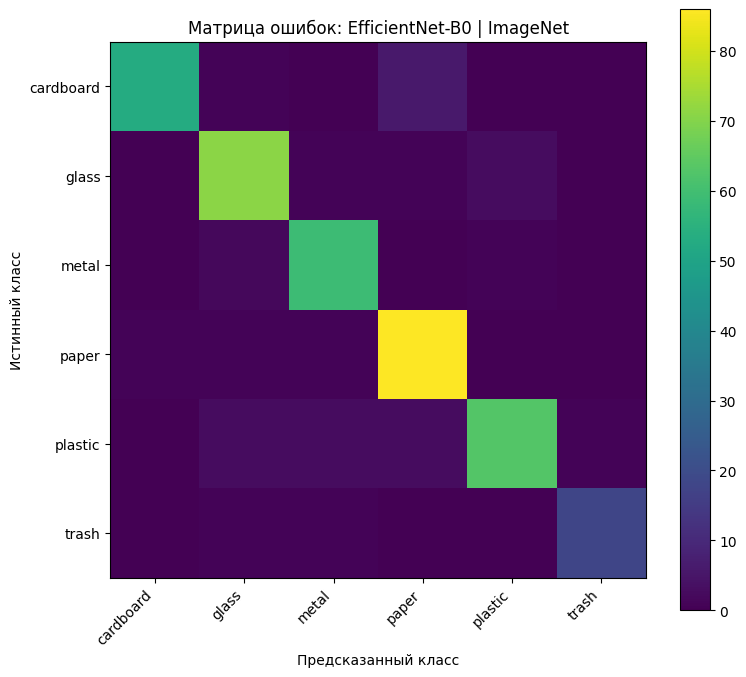

In [28]:
cm = confusion_matrix(
    best_result["y_true"],
    best_result["y_pred"],
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm)
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title(f"Матрица ошибок: {best_result['name']}")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()